# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Krishna 2021's ccRCC malignant manifold is **non-branching**: the gastrulation /
somitogenesis / neural-crest developmental signatures form a single monotone gradient
(a **posterior-somitogenesis → neural-crest** axis) rather than a hub radiating into
two competing arms. The correct topology is therefore a **principal curve** (ElPiGraph,
non-branching by construction) fit on the *joint* embedding — **not** a re-embedding
(re-embedding an anisotropic compartment fabricates folds).

**Scope decision (derived, not inherited).** 01 found a single compartment (one Leiden
lobe, ~5% cycling throughout), so — unlike Kürten 2021, which confined its axis to a
low-cycling lobe — there is no proliferation lobe to exclude: the whole malignant
manifold is the trajectory object. The curve is rooted at the somitogenesis-high tip
(developmental origin) and pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding.
The three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are
scored against the shared **union** control pool and graph-smoothed to read geography
rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 5006 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.44
Gast: 70/81 genes present
pSom: 82/98 genes present
Crest: 94/104 genes present


### Geometry decision — branching vs non-branching (data-driven)
Read whether Gast and pSom split into two competing arms (branching, Puram case) or
co-vary as one gradient (non-branching). Two facts settle it here: (i) the dominant
spatial axis is **pSom ↔ Crest** (strongly anti-correlated), an inverse gradient;
(ii) Gast is weak and diffuse (near-flat, only weakly anti-correlated with pSom), so
there is no Gast/pSom hub-and-arms structure. Global module means place **pSom** as the
strongest program (Linear-pSom/Crest, matching prior Kidney runs). This is the
non-branching case: **Gate 2 = GO**, no bifurcation for **Gate 3 = NA**.

In [4]:
print('global module means (raw score_genes):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('\nsmoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.3f}')
print('-> dominant axis is pSom<->Crest inverse gradient; Gast weak/diffuse -> non-branching.')
sub = adata   # whole manifold is the trajectory object

global module means (raw score_genes): {'Gast': -0.0393, 'pSom': 0.0443, 'Crest': -0.0419}

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.102
  Crest_sm vs Gast_sm: r = -0.269
  Crest_sm vs pSom_sm: r = -0.890
-> dominant axis is pSom<->Crest inverse gradient; Gast weak/diffuse -> non-branching.


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu=100` is strong
bending regularisation, keeping the arc smooth. The fold diagnostic and tip/fork counts
are checked at two node counts for robustness before committing to Nodes=20.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for NODES in [20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=NODES, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(sub)
    print(f'Nodes={NODES}: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f}')
# commit to Nodes=20
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve (Nodes=20): {tips} tips, {forks} forks | self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

Nodes=20: 2 tips, 0 forks | fold self-approach ratio = 2.98
Nodes=30: 2 tips, 0 forks | fold self-approach ratio = 2.52
committed curve (Nodes=20): 2 tips, 0 forks | self-approach ratio = 2.98 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the
developmental origin. Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0413 pSom=+0.0359 Crest=-0.0293
tip 2: Gast=-0.0391 pSom=+0.0495 Crest=-0.0472
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.036 p=1.0e-02
  pSom_sm: rho=-0.848 p=0.0e+00
  Crest_sm: rho=+0.749 p=0.0e+00
  cyc_score: rho=-0.229 p=1.7e-60


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign/axis choice, no rotation — an SVD
basis can silently reflect an axis). This dataset's trajectory is already **horizontal**
in the raw embedding (corr(raw_x, t) = -0.98, corr(raw_y, t) ≈ 0), so the house
transform is identity on the axes with a **sign flip on x** to send low pseudotime to
the left. The assertion confirms it.

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])        # already horizontal: keep axes
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left (x-flip only)
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: identity + x-flip (already horizontal); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: identity + x-flip (already horizontal); corr(x_lin, pseudotime) = +0.98


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


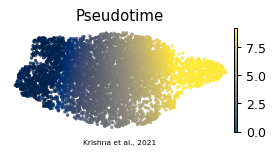

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Krishna et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')